<a href="https://colab.research.google.com/github/Dineeesh2906/Deep-learning---24BAD021/blob/main/24BAD021_ass3_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:
vocab_size = 10000
max_length = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000


In [ ]:
X_train = pad_sequences(
    X_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (25000, 200)
X_test shape: (25000, 200)


In [ ]:
def create_rnn_model():

    model = Sequential([
        Embedding(vocab_size, 128, input_length=max_length),

        SimpleRNN(64),

        Dropout(0.5),

        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
def create_lstm_model():

    model = Sequential([
        Embedding(vocab_size, 128, input_length=max_length),

        LSTM(64),

        Dropout(0.5),

        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
def create_gru_model():

    model = Sequential([
        Embedding(vocab_size, 128, input_length=max_length),

        GRU(64),

        Dropout(0.5),

        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
def train_and_evaluate(model, model_name):

    print("\n" + "=" * 50)
    print("Training:", model_name)
    print("=" * 50)

    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,
        epochs=5,
        batch_size=64,
        validation_split=0.2,
        verbose=1
    )

    training_time = time.time() - start_time

    # Prediction
    y_probability = model.predict(X_test)

    y_pred = (y_probability >= 0.5).astype(int).flatten()

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred
    )

    recall = recall_score(
        y_test,
        y_pred
    )

    f1 = f1_score(
        y_test,
        y_pred
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Training Time (sec)": training_time
    }, history

In [ ]:
rnn_model = create_rnn_model()

rnn_results, rnn_history = train_and_evaluate(
    rnn_model,
    "Simple RNN"
)

print(rnn_results)


Training: Simple RNN
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - accuracy: 0.5026 - loss: 0.7012 - val_accuracy: 0.5090 - val_loss: 0.6932
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 87ms/step - accuracy: 0.6086 - loss: 0.6421 - val_accuracy: 0.5144 - val_loss: 0.7191
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 43s 92ms/step - accuracy: 0.7007 - loss: 0.5049 - val_accuracy: 0.5104 - val_loss: 0.7989
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 88ms/step - accuracy: 0.7425 - loss: 0.4174 - val_accuracy: 0.5060 - val_loss: 0.8622
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 87ms/step - accuracy: 0.7630 - loss: 0.3727 - val_accuracy: 0.5034 - val_loss: 0.9211
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step
{'Model': 'Simple RNN', 'Accuracy': 0.5038, 'Precision': 0.5037181996086105, 'Recall': 0.5148, 'F1-Score': 0.5091988130563798, 'Training Time (sec)': 179.54981660842896}


In [ ]:
lstm_model = create_lstm_model()

lstm_results, lstm_history = train_and_evaluate(
    lstm_model,
    "LSTM"
)

print(lstm_results)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



Training: LSTM
Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 79s 236ms/step - accuracy: 0.5315 - loss: 0.6916 - val_accuracy: 0.5144 - val_loss: 0.6913
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 79s 252ms/step - accuracy: 0.5595 - loss: 0.6847 - val_accuracy: 0.5690 - val_loss: 0.6712
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 75s 238ms/step - accuracy: 0.6756 - loss: 0.6139 - val_accuracy: 0.6270 - val_loss: 0.6723
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 74s 237ms/step - accuracy: 0.6783 - loss: 0.5920 - val_accuracy: 0.6858 - val_loss: 0.6151
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 74s 235ms/step - accuracy: 0.7872 - loss: 0.5125 - val_accuracy: 0.5014 - val_loss: 0.8158
782/782 ━━━━━━━━━━━━━━━━━━━━ 24s 30ms/step
{'Model': 'LSTM', 'Accuracy': 0.50856, 'Precision': 0.5043190441591991, 'Recall': 0.99952, 'F1-Score': 0.6703868648387616, 'Training Time (sec)': 379.97367238998413}


In [ ]:
gru_model = create_gru_model()

gru_results, gru_history = train_and_evaluate(
    gru_model,
    "GRU"
)

print(gru_results)


Training: GRU
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


313/313 ━━━━━━━━━━━━━━━━━━━━ 91s 274ms/step - accuracy: 0.5143 - loss: 0.6924 - val_accuracy: 0.5398 - val_loss: 0.6890
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 256ms/step - accuracy: 0.6382 - loss: 0.6390 - val_accuracy: 0.7300 - val_loss: 0.5677
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 83s 258ms/step - accuracy: 0.7884 - loss: 0.4916 - val_accuracy: 0.7444 - val_loss: 0.5694
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 255ms/step - accuracy: 0.8558 - loss: 0.3562 - val_accuracy: 0.8590 - val_loss: 0.3453
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 256ms/step - accuracy: 0.9209 - loss: 0.2186 - val_accuracy: 0.8608 - val_loss: 0.3433
782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step
{'Model': 'GRU', 'Accuracy': 0.83976, 'Precision': 0.873855633802817, 'Recall': 0.79416, 'F1-Score': 0.8321039396479464, 'Training Time (sec)': 416.4817337989807}


In [ ]:
results = pd.DataFrame([
    rnn_results,
    lstm_results,
    gru_results
])

results

,Model,Accuracy,Precision,Recall,F1-Score,Training Time (sec)
0,Simple RNN,0.50380,0.503718,0.51480,0.509199,179.549817
1,LSTM,0.50856,0.504319,0.99952,0.670387,379.973672
2,GRU,0.83976,0.873856,0.79416,0.832104,416.481734


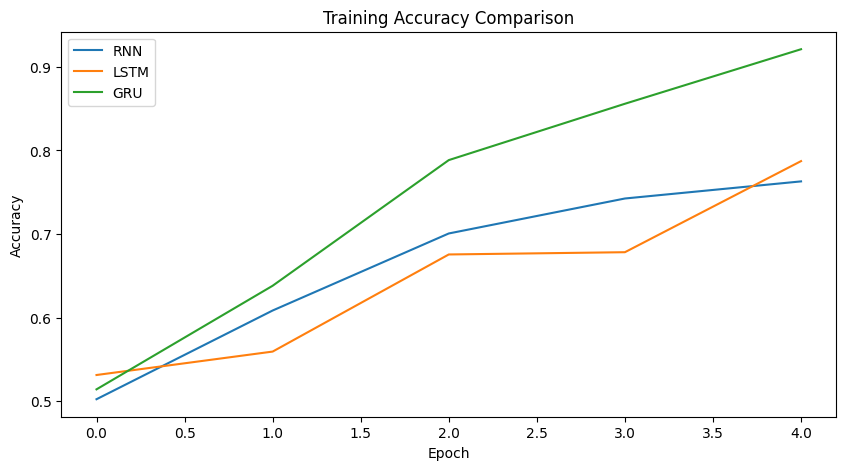

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    rnn_history.history['accuracy'],
    label='RNN'
)

plt.plot(
    lstm_history.history['accuracy'],
    label='LSTM'
)

plt.plot(
    gru_history.history['accuracy'],
    label='GRU'
)

plt.title("Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

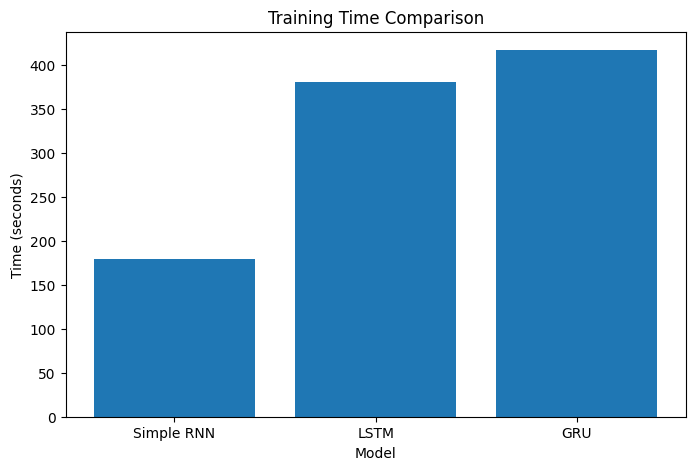

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["Training Time (sec)"]
)

plt.title("Training Time Comparison")
plt.xlabel("Model")
plt.ylabel("Time (seconds)")

plt.show()